# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло. Він лежить в архіві демо-матеріалів лекції 3 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. KNN заповнює пропуски на основі схожих записів. Він враховує взаємозв’язки між даними, але залежить від вибору кількості сусідів і масштабування ознак.
2. Під час навчання використовували MSE для мінімізації помилки. Після навчання оцінювали якість моделі за метриками на тестових даних.
3. Порівнювали помилки навчання та валідації, щоб оцінити якість моделі й виявити можливе перенавчання.
4. Це проста модель для порівняння. Для регресії вона може прогнозувати середнє значення цільової змінної.
5. Створити випадкові значення \(x\), застосувати до них ReLU, Sigmoid, Tanh, LeakyReLU та ELU й побудувати графіки через Matplotlib.
6. Для повнозв’язного шару формула: \(P=n_{in}\cdot n_{out}+n_{out}\), де враховуються ваги та зміщення.
7. Це визначають за графіками втрат. Якщо валідаційна помилка зростає, можливе перенавчання; якщо втрати перестали зменшуватися — навчання можна завершувати.

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [ ]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Поліщук Анастасія Ігорівна"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#1): King County House Sales


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [ ]:

!pip install -q datasets pyarrow

from datasets import load_dataset

# Завантаження King County House Sales
HF_URL = (
    "https://huggingface.co/datasets/kraina/house_sales_in_king_county/"
    "resolve/main/data/house_sales_king_county.parquet"
)

housing_dataset = load_dataset(
    "parquet",
    data_files=HF_URL
)

print(housing_dataset)


data/house_sales_king_county.parquet: reconstructing file:   0%|          |  0.00B /  730kB            

data/house_sales_king_county.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15'],
        num_rows: 21613
    })
})


In [ ]:

# Перетворення датасету на pandas DataFrame

housing_df = housing_dataset["train"].to_pandas()

print("Загальний розмір таблиці:", housing_df.shape)

print("\nНазви стовпців:")
print(housing_df.columns.tolist())

display(housing_df.head())


Загальний розмір таблиці: (21613, 21)

Назви стовпців:
['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:

from sklearn.model_selection import train_test_split

SEED = 42

# Поділ до EDA та обробки пропусків
train_df, temp_df = train_test_split(
    housing_df,
    test_size=0.4,
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED
)

print(f"Розмір навчальної вибірки (train): {train_df.shape}")
print(f"Розмір валідаційної вибірки (val): {val_df.shape}")
print(f"Розмір тестової вибірки (test): {test_df.shape}")


Розмір навчальної вибірки (train): (12967, 21)
Розмір валідаційної вибірки (val): (4323, 21)
Розмір тестової вибірки (test): (4323, 21)


In [ ]:
# Перегляд перших п'яти рядків навчальної вибірки
train_df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
2679,6791400800,20150413T000000,347500.0,3,1.00,1830,12036,1.0,0,0,...,7,1550,280,1977,0,98042,47.3126,-122.043,1810,12036
18912,2425049066,20140616T000000,1920000.0,4,2.50,3070,34412,1.0,0,3,...,9,2070,1000,1950,0,98039,47.6400,-122.240,3780,27940
18208,2579500110,20140701T000000,2367000.0,3,2.25,3530,17450,1.0,1,3,...,9,1840,1690,1930,1993,98040,47.5358,-122.213,3530,17310
17819,2420069268,20140821T000000,184900.0,2,1.00,1230,5000,1.0,0,0,...,6,1230,0,1911,0,98022,47.2064,-121.988,1230,5413
9459,721049096,20140527T000000,569950.0,5,4.50,4850,40902,2.0,0,0,...,10,4850,0,2001,0,98023,47.3181,-122.344,1640,13503


In [ ]:
# Перевірка типів даних і кількості непорожніх значень
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12967 entries, 2679 to 15795
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             12967 non-null  int64  
 1   date           12967 non-null  object 
 2   price          12967 non-null  float64
 3   bedrooms       12967 non-null  int64  
 4   bathrooms      12967 non-null  float64
 5   sqft_living    12967 non-null  int64  
 6   sqft_lot       12967 non-null  int64  
 7   floors         12967 non-null  float64
 8   waterfront     12967 non-null  int64  
 9   view           12967 non-null  int64  
 10  condition      12967 non-null  int64  
 11  grade          12967 non-null  int64  
 12  sqft_above     12967 non-null  int64  
 13  sqft_basement  12967 non-null  int64  
 14  yr_built       12967 non-null  int64  
 15  yr_renovated   12967 non-null  int64  
 16  zipcode        12967 non-null  int64  
 17  lat            12967 non-null  float64
 18  long    

In [ ]:
# Основні статистичні характеристики числових стовпців
train_df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,1.296700e+04,1.296700e+04,12967.000000,12967.000000,12967.000000,1.296700e+04,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000,12967.000000
mean,4.577285e+09,5.371415e+05,3.362227,2.112844,2073.849156,1.497418e+04,1.499267,0.006864,0.232513,3.410349,7.651731,1784.381198,289.467957,1971.128480,84.640549,98078.373487,47.560523,-122.214838,1980.762088,12704.341251
std,2.865659e+09,3.534918e+05,0.899535,0.763987,906.092176,3.959637e+04,0.543229,0.082565,0.759635,0.650557,1.171385,821.538302,440.518943,29.406463,402.194555,53.404624,0.139000,0.140130,681.468215,26740.097647
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.159300,-122.519000,399.000000,651.000000
25%,2.130555e+09,3.210000e+05,3.000000,1.750000,1420.000000,5.000000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1200.000000,0.000000,1951.000000,0.000000,98033.000000,47.471600,-122.329000,1480.000000,5080.000000
50%,3.904931e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.565000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98070.000000,47.572900,-122.233000,1830.000000,7600.000000
75%,7.300001e+09,6.400000e+05,4.000000,2.500000,2550.000000,1.066000e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2190.000000,560.000000,1997.000000,0.000000,98118.000000,47.678500,-122.125000,2360.000000,10051.000000
max,9.900000e+09,7.700000e+06,10.000000,8.000000,12050.000000,1.164794e+06,3.500000,1.000000,4.000000,5.000000,13.000000,8570.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.316000,6210.000000,871200.000000


In [ ]:
# Перевірка пропущених значень у навчальній вибірці

missing_values = train_df.isnull().sum()

print("Кількість пропусків у кожному стовпці:")
print(missing_values)

print("\nЗагальна кількість пропусків:", missing_values.sum())

Кількість пропусків у кожному стовпці:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Загальна кількість пропусків: 0


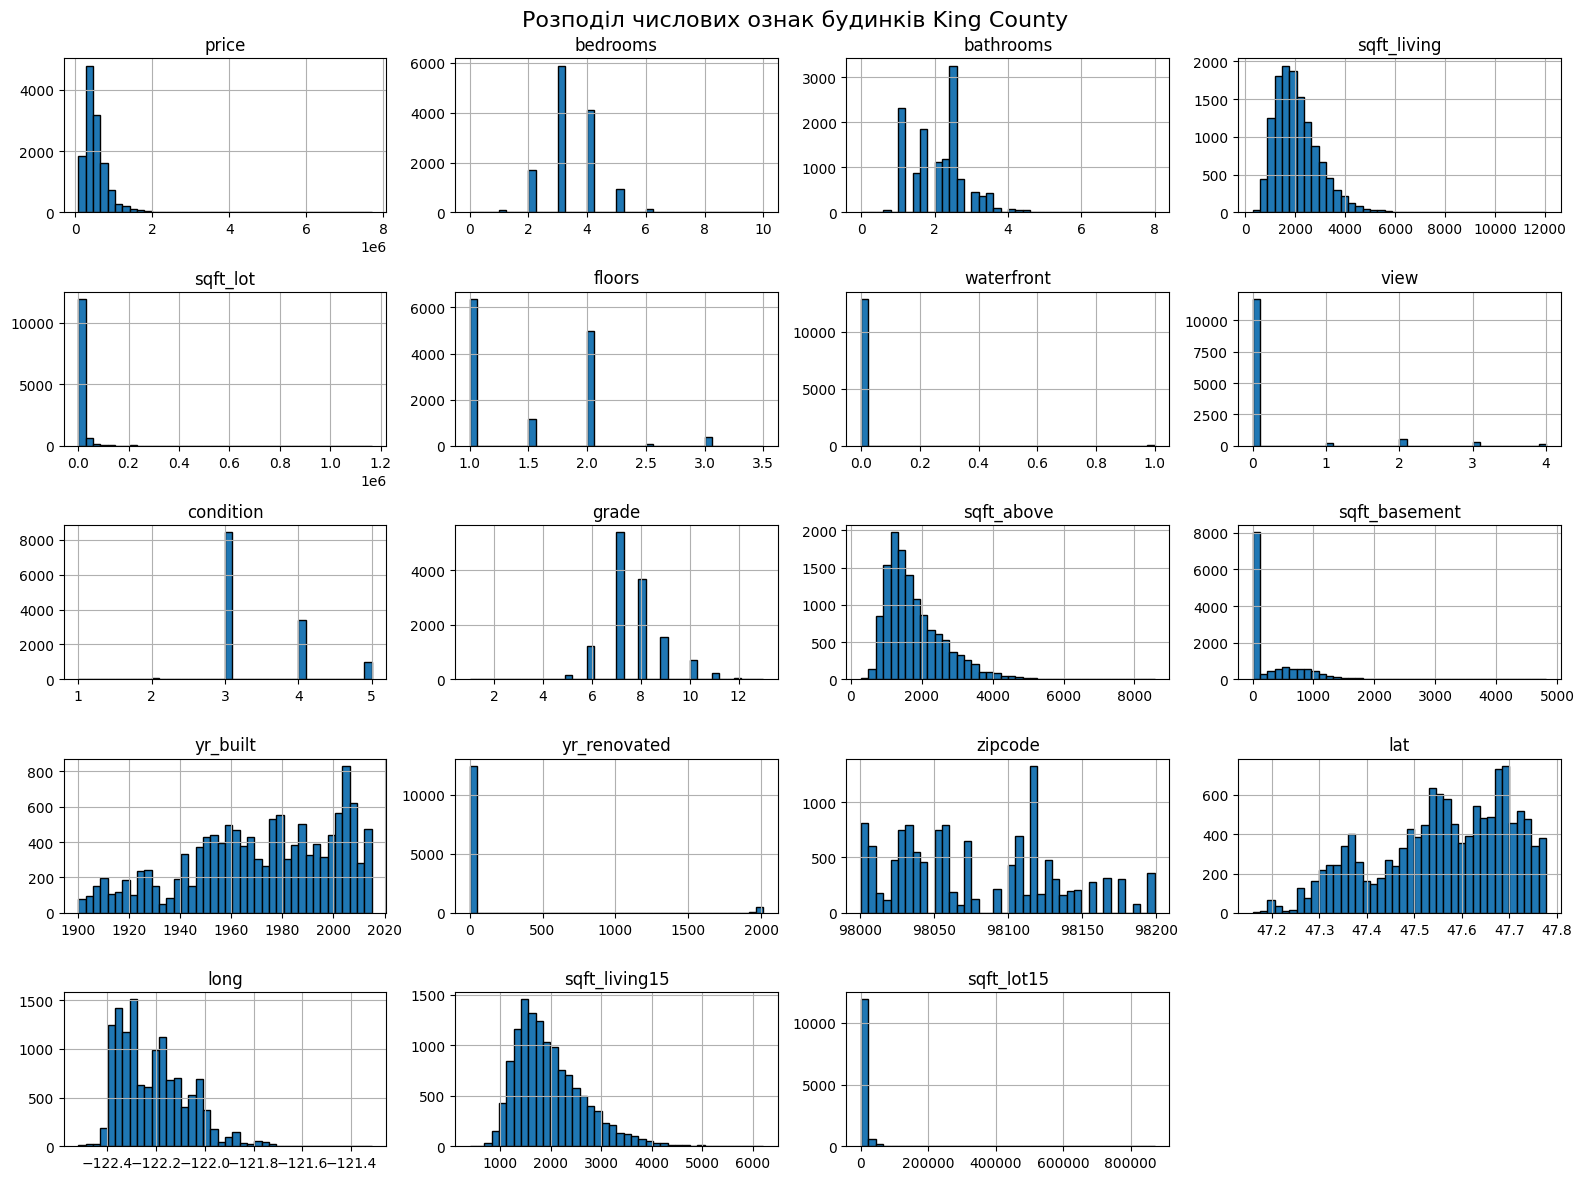

In [ ]:

import matplotlib.pyplot as plt

# Аналіз розподілу числових ознак на train-вибірці
numeric_features = train_df.select_dtypes(include="number").drop(
    columns=["id"],
    errors="ignore"
)

numeric_features.hist(
    bins=40,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle(
    "Розподіл числових ознак будинків King County",
    fontsize=16
)

plt.tight_layout()
plt.show()


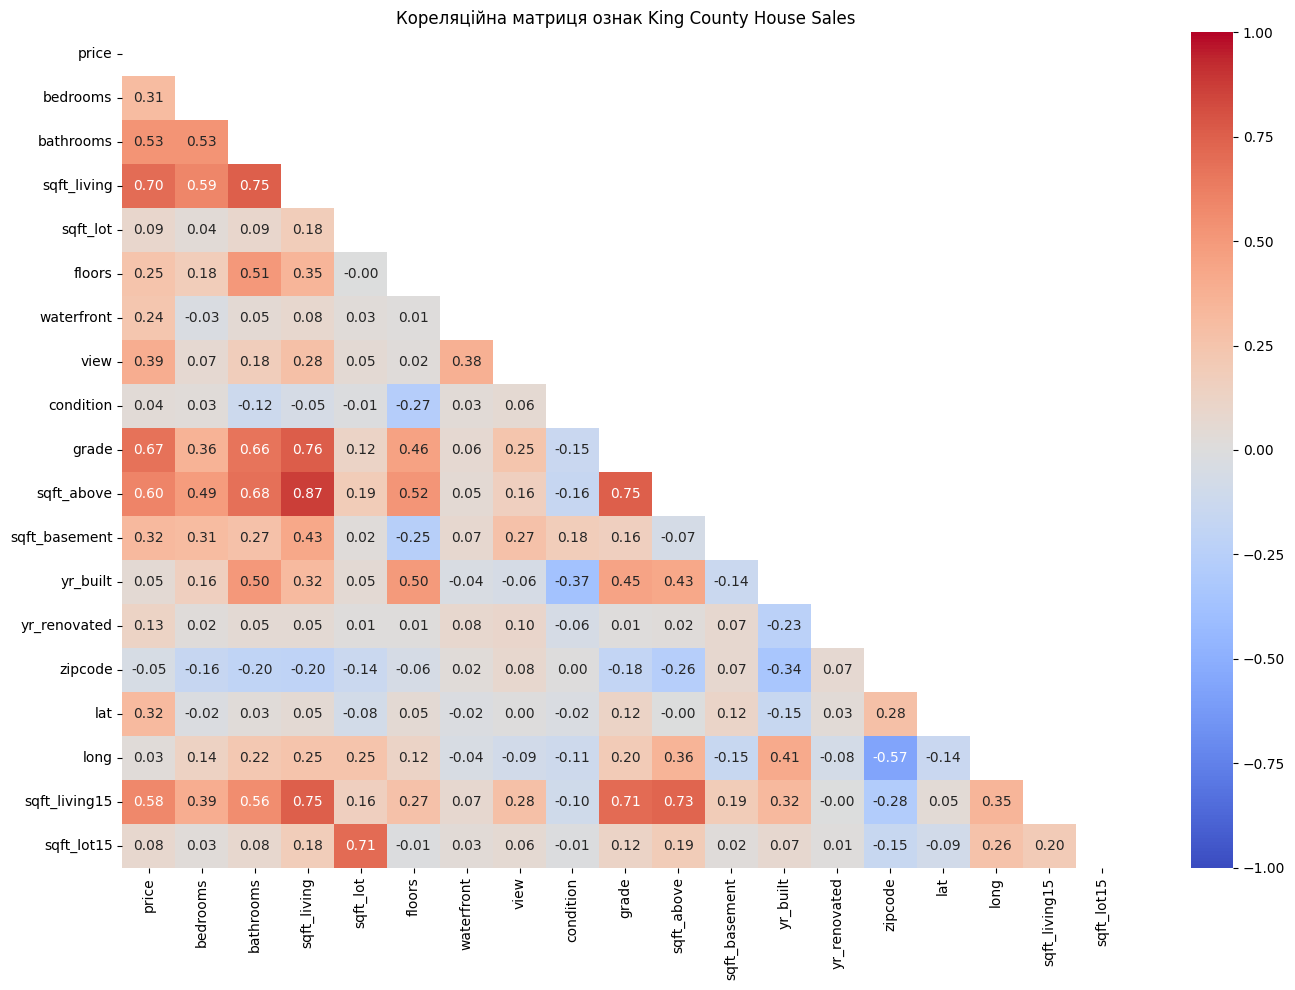

In [ ]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Використовуємо лише числові ознаки, без ідентифікатора
corr_df = train_df.select_dtypes(include="number").drop(
    columns=["id"],
    errors="ignore"
)

corr = corr_df.corr()

# Приховуємо верхній трикутник матриці
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    mask=mask,
    vmin=-1,
    vmax=1,
    center=0,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Кореляційна матриця ознак King County House Sales")
plt.tight_layout()
plt.show()


**Аналіз кореляційної матриці.** За результатами аналізу навчальної вибірки King County House Sales виявлено позитивний лінійний зв’язок між ціною будинку (`price`) та його житловою площею (`sqft_living`), коефіцієнт кореляції становить 0,70. Також помітний зв’язок ціни з оцінкою якості будинку (`grade`) — 0,67, а з площею надземної частини (`sqft_above`) — приблизно 0,61.

Серед ознак спостерігається мультиколінеарність. Зокрема, кореляція між `sqft_living` і `sqft_above` становить приблизно 0,87, а між `sqft_living` і `grade` — 0,76. Ознаки `sqft_lot` і `sqft_lot15` також мають сильний зв’язок — 0,71. Це пояснюється тим, що відповідні характеристики будинків і земельних ділянок пов’язані між собою.

Отже, житлова площа та оцінка якості є важливими кандидатами для прогнозування ціни. Водночас виявлені кореляції між ознаками потрібно врахувати під час підготовки даних до навчання моделей. Самі по собі вони не є достатньою підставою для автоматичного видалення ознак.

In [ ]:
skewness = numeric_features.skew().sort_values(ascending=False)

print("Асиметрія розподілів:")
display(skewness.to_frame(name="Skewness"))

Асиметрія розподілів:


,Skewness
sqft_lot,11.994942
waterfront,11.947241
sqft_lot15,9.107908
yr_renovated,4.541999
price,3.605314
view,3.392939
sqft_basement,1.588573
sqft_above,1.410222
sqft_living,1.337787
sqft_living15,1.095049


**Аналіз розподілів числових ознак.** За результатами побудови гістограм і розрахунку коефіцієнтів асиметрії встановлено, що частина ознак датасету King County House Sales має правосторонньо скошений розподіл. Найбільша асиметрія спостерігається для площ ділянок `sqft_lot` (11,99) і `sqft_lot15` (9,11), а також для ціни будинку `price` (3,61). Це свідчить про наявність невеликої кількості дуже великих значень порівняно з основною частиною спостережень.

Ознаки `waterfront` і `view` також мають високі коефіцієнти асиметрії, що пов’язано з нерівномірним розподілом їхніх значень. Для `yr_renovated` асиметрія може пояснюватися великою кількістю будинків із нульовим значенням року реконструкції.

Отже, під час підготовки даних необхідно врахувати відмінності в масштабах ознак і наявність потенційних викидів. Водночас високий коефіцієнт асиметрії не є достатньою підставою для видалення спостережень: спочатку потрібно перевірити їхню правдоподібність і вплив на навчання моделей.

In [ ]:

# Перевірка крайніх значень і потенційних викидів

columns_to_check = [
    "price",
    "sqft_living",
    "sqft_lot",
    "sqft_lot15",
    "sqft_basement",
    "yr_renovated"
]

for col in columns_to_check:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (train_df[col] < lower_bound) |
        (train_df[col] > upper_bound)
    )

    print(f"\nОзнака: {col}")
    print(f"Мінімум: {train_df[col].min():,.2f}")
    print(f"Максимум: {train_df[col].max():,.2f}")
    print(f"Нижня межа IQR: {lower_bound:,.2f}")
    print(f"Верхня межа IQR: {upper_bound:,.2f}")
    print(f"Кількість значень за межами IQR: {outliers.sum()}")



Ознака: price
Мінімум: 75,000.00
Максимум: 7,700,000.00
Нижня межа IQR: -157,500.00
Верхня межа IQR: 1,118,500.00
Кількість значень за межами IQR: 689

Ознака: sqft_living
Мінімум: 290.00
Максимум: 12,050.00
Нижня межа IQR: -275.00
Верхня межа IQR: 4,245.00
Кількість значень за межами IQR: 321

Ознака: sqft_lot
Мінімум: 520.00
Максимум: 1,164,794.00
Нижня межа IQR: -3,490.00
Верхня межа IQR: 19,150.00
Кількість значень за межами IQR: 1468

Ознака: sqft_lot15
Мінімум: 651.00
Максимум: 871,200.00
Нижня межа IQR: -2,376.50
Верхня межа IQR: 17,507.50
Кількість значень за межами IQR: 1329

Ознака: sqft_basement
Мінімум: 0.00
Максимум: 4,820.00
Нижня межа IQR: -840.00
Верхня межа IQR: 1,400.00
Кількість значень за межами IQR: 290

Ознака: yr_renovated
Мінімум: 0.00
Максимум: 2,015.00
Нижня межа IQR: 0.00
Верхня межа IQR: 0.00
Кількість значень за межами IQR: 550


### 1.7. Обробка викидів

Для виявлення потенційних викидів використано метод міжквартильного розмаху (IQR). За його допомогою перевірено ціну будинків (`price`), житлову площу (`sqft_living`), площі земельних ділянок (`sqft_lot`, `sqft_lot15`), площу підвалу (`sqft_basement`) та рік реконструкції (`yr_renovated`).

Найбільшу кількість потенційних викидів виявлено для площ земельних ділянок: 1468 значень у `sqft_lot` та 1329 значень у `sqft_lot15`. Для ціни будинків за межі IQR виходять 689 значень, для житлової площі — 321, а для площі підвалу — 290.

Виявлені значення не видалялися автоматично, оскільки великі площі та висока вартість можуть відповідати реальним характеристикам нерухомості. Метод IQR визначає статистично незвичні спостереження, але не доводить, що вони є помилковими.

Для ознаки `yr_renovated` застосування стандартного правила IQR має обмеження: через значну кількість нульових значень верхня межа інтервалу становить нуль. Ненульові значення року реконструкції є допустимими та не повинні видалятися лише через результат цього правила.

Отже, на цьому етапі вирішено зберегти початкові спостереження. Вплив асиметрії числових ознак планується врахувати під час підготовки даних до навчання моделей шляхом стандартизації та, за потреби, логарифмічного перетворення окремих ознак.

### 1.8. Інженерія ознак

За результатами кореляційного аналізу виявлено взаємозв’язок між деякими ознаками датасету. Зокрема, `sqft_living` і `sqft_above` описують пов’язані характеристики площі будинку, а `sqft_lot` і `sqft_lot15` — площі земельної ділянки. Також помітна кореляція між `sqft_living` і `sqft_living15`.

Видаляти ці ознаки лише на підставі кореляції недоцільно, оскільки кожна з них може містити корисну інформацію для прогнозування ціни. Тому на початковому етапі всі ознаки, крім ідентифікатора `id`, буде збережено. Ідентифікатор не використовуватиметься як предиктор, оскільки його числове значення саме по собі не характеризує властивості будинку.

Для підвищення ефективності навчання числові ознаки буде стандартизовано. Параметри стандартизації обчислюватимуться лише за навчальною вибіркою, щоб уникнути витоку інформації з валідаційної та тестової вибірок.

In [ ]:

import numpy as np
import pandas as pd
import torch

from sklearn.preprocessing import StandardScaler

# Фіксуємо випадковість для відтворюваності результатів
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Перетворюємо дату продажу на два числові показники
def prepare_features(df):
    data = df.copy()

    sale_date = pd.to_datetime(
        data["date"],
        format="%Y%m%dT%H%M%S"
    )

    data["sale_year"] = sale_date.dt.year
    data["sale_month"] = sale_date.dt.month

    # id не використовуємо, бо це ідентифікатор, а не характеристика будинку
    # date замінено на sale_year і sale_month
    data = data.drop(columns=["id", "date", "price"])

    return data.astype("float32")

# Формуємо ознаки окремо для кожної вибірки
X_train_df = prepare_features(train_df)
X_val_df = prepare_features(val_df)
X_test_df = prepare_features(test_df)

# Цільова змінна — ціна будинку
y_train = train_df["price"].to_numpy(dtype=np.float32).reshape(-1, 1)
y_val = val_df["price"].to_numpy(dtype=np.float32).reshape(-1, 1)
y_test = test_df["price"].to_numpy(dtype=np.float32).reshape(-1, 1)

# Стандартизуємо ознаки: навчаємо scaler лише на train
scaler_X = StandardScaler()

X_train = scaler_X.fit_transform(X_train_df).astype(np.float32)
X_val = scaler_X.transform(X_val_df).astype(np.float32)
X_test = scaler_X.transform(X_test_df).astype(np.float32)

# Стандартизуємо цільову змінну для стабільнішого навчання
# Під час оцінювання повернемо прогноз до початкових доларів
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train).astype(np.float32)
y_val_scaled = scaler_y.transform(y_val).astype(np.float32)
y_test_scaled = scaler_y.transform(y_test).astype(np.float32)

print("Кількість ознак:", X_train.shape[1])
print("Train:", X_train.shape, y_train_scaled.shape)
print("Validation:", X_val.shape, y_val_scaled.shape)
print("Test:", X_test.shape, y_test_scaled.shape)


Кількість ознак: 20
Train: (12967, 20) (12967, 1)
Validation: (4323, 20) (4323, 1)
Test: (4323, 20) (4323, 1)


In [ ]:

import torch

# Вибираємо GPU, якщо доступний, інакше використовуємо CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій для навчання:", device)

def to_tensor(X, y):
    X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
    y_tensor = torch.tensor(y, dtype=torch.float32).to(device)
    return X_tensor, y_tensor

x_train_t, y_train_t = to_tensor(X_train, y_train_scaled)
x_val_t, y_val_t = to_tensor(X_val, y_val_scaled)
x_test_t, y_test_t = to_tensor(X_test, y_test_scaled)

print("Train:", x_train_t.shape, y_train_t.shape)
print("Validation:", x_val_t.shape, y_val_t.shape)
print("Test:", x_test_t.shape, y_test_t.shape)


Пристрій для навчання: cpu
Train: torch.Size([12967, 20]) torch.Size([12967, 1])
Validation: torch.Size([4323, 20]) torch.Size([4323, 1])
Test: torch.Size([4323, 20]) torch.Size([4323, 1])


In [ ]:

import os
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

# Папки для збереження логів і моделей
RUNS_DIR = "runs"
MODELS_DIR = "models"

os.makedirs(RUNS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

N_EPOCHS = 100
n_features = X_train.shape[1]

linear_model = torch.nn.Linear(
    in_features=n_features,
    out_features=1
).to(device)

optimizer = torch.optim.SGD(
    linear_model.parameters(),
    lr=0.01
)

loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "linear")
)

train_losses = []
val_losses = []

for epoch in range(N_EPOCHS):
    linear_model.train()

    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    train_loss = loss.item()
    train_losses.append(train_loss)

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            linear_model(x_val_t),
            y_val_t
        ).item()

    val_losses.append(val_loss)

    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Epoch {epoch + 1:3d}/{N_EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f}"
        )

writer.close()


Epoch   1/100 | train_loss=0.7249 | val_loss=0.7336
Epoch  11/100 | train_loss=0.5519 | val_loss=0.5726
Epoch  21/100 | train_loss=0.4732 | val_loss=0.4964
Epoch  31/100 | train_loss=0.4267 | val_loss=0.4505
Epoch  41/100 | train_loss=0.3963 | val_loss=0.4202
Epoch  51/100 | train_loss=0.3754 | val_loss=0.3991
Epoch  61/100 | train_loss=0.3603 | val_loss=0.3838
Epoch  71/100 | train_loss=0.3491 | val_loss=0.3723
Epoch  81/100 | train_loss=0.3404 | val_loss=0.3634
Epoch  91/100 | train_loss=0.3337 | val_loss=0.3564
Epoch 100/100 | train_loss=0.3287 | val_loss=0.3513


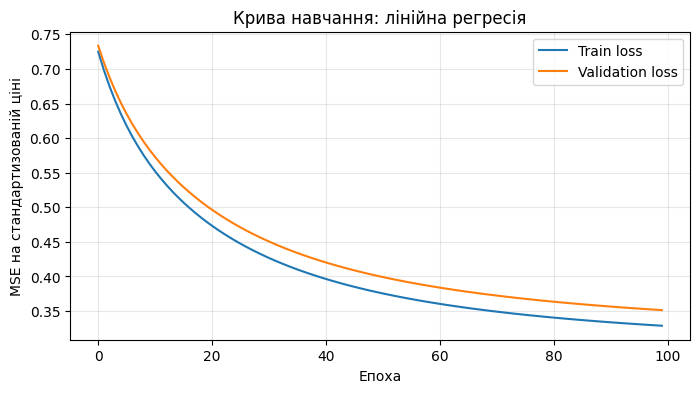

In [ ]:

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("MSE на стандартизованій ціні")
plt.title("Крива навчання: лінійна регресія")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import os
import torch

# Перевіряємо модель на тестових даних
linear_model.eval()

with torch.no_grad():
    y_test_pred_scaled = linear_model(x_test_t).cpu().numpy()

# Повертаємо прогнозовані значення до початкової шкали цін
y_test_pred = scaler_y.inverse_transform(y_test_pred_scaled).ravel()
y_test_true = y_test.ravel()

# Бейзлайн: прогнозуємо середню ціну з тренувальної вибірки
baseline_pred = np.full_like(y_test_true, y_train.mean())

def report_metrics(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(
        f"{model_name}: "
        f"MSE={mse:.2f}, "
        f"RMSE={rmse:.2f}, "
        f"MAE={mae:.2f}, "
        f"R²={r2:.4f}"
    )

report_metrics(y_test_true, baseline_pred, "Бейзлайн")
report_metrics(y_test_true, y_test_pred, "Лінійна регресія")


Бейзлайн: MSE=168165998592.00, RMSE=410080.48, MAE=242663.61, R²=-0.0009
Лінійна регресія: MSE=58806947840.00, RMSE=242501.44, MAE=135229.02, R²=0.6500


In [ ]:

os.makedirs("models", exist_ok=True)

torch.save(
    linear_model.cpu().state_dict(),
    "models/linear.pt"
)

linear_model.to(device)

print("Модель збережено: models/linear.pt")


Модель збережено: models/linear.pt


3. Створення нейромережі

In [ ]:

housing_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(housing_nn)
print(
    "Кількість параметрів NN:",
    sum(p.numel() for p in housing_nn.parameters())
)
print(
    "Кількість параметрів лінійної:",
    sum(p.numel() for p in linear_model.parameters())
)


Sequential(
  (0): Linear(in_features=20, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN: 3457
Кількість параметрів лінійної: 21


In [ ]:

N_EPOCHS = 200

optimizer = torch.optim.Adam(housing_nn.parameters(), lr=0.001)
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "neural_network")
)

nn_train_losses, nn_val_losses = [], []

for epoch in range(N_EPOCHS):
    housing_nn.train()

    optimizer.zero_grad()
    y_pred = housing_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    nn_train_losses.append(loss.item())

    housing_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(housing_nn(x_val_t), y_val_t).item()

    nn_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"Epoch {epoch + 1:3d}/{N_EPOCHS} | "
            f"train_loss={loss.item():.4f} | "
            f"val_loss={val_loss:.4f}"
        )

writer.close()


Epoch   1/200 | train_loss=0.9809 | val_loss=1.0075
Epoch  11/200 | train_loss=0.7697 | val_loss=0.7840
Epoch  21/200 | train_loss=0.5501 | val_loss=0.5571
Epoch  31/200 | train_loss=0.3905 | val_loss=0.4073
Epoch  41/200 | train_loss=0.3212 | val_loss=0.3448
Epoch  51/200 | train_loss=0.2798 | val_loss=0.3033
Epoch  61/200 | train_loss=0.2565 | val_loss=0.2822
Epoch  71/200 | train_loss=0.2389 | val_loss=0.2674
Epoch  81/200 | train_loss=0.2268 | val_loss=0.2560
Epoch  91/200 | train_loss=0.2177 | val_loss=0.2480
Epoch 101/200 | train_loss=0.2098 | val_loss=0.2411
Epoch 111/200 | train_loss=0.2029 | val_loss=0.2348
Epoch 121/200 | train_loss=0.1965 | val_loss=0.2293
Epoch 131/200 | train_loss=0.1906 | val_loss=0.2243
Epoch 141/200 | train_loss=0.1851 | val_loss=0.2196
Epoch 151/200 | train_loss=0.1799 | val_loss=0.2152
Epoch 161/200 | train_loss=0.1750 | val_loss=0.2109
Epoch 171/200 | train_loss=0.1701 | val_loss=0.2068
Epoch 181/200 | train_loss=0.1654 | val_loss=0.2028
Epoch 191/20

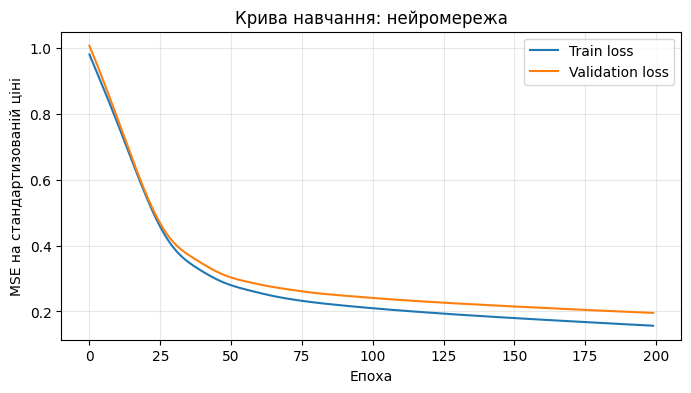

In [ ]:

plt.figure(figsize=(8, 4))
plt.plot(nn_train_losses, label="Train loss")
plt.plot(nn_val_losses, label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("MSE на стандартизованій ціні")
plt.title("Крива навчання: нейромережа")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

import os
os.makedirs("models", exist_ok=True)

torch.save(housing_nn.cpu().state_dict(), "models/nn_v1.pt")
housing_nn.to(device)

print("Модель збережено: models/nn_v1.pt")





Модель збережено: models/nn_v1.pt


In [ ]:

housing_nn.eval()

with torch.no_grad():
    y_test_pred_nn_scaled = housing_nn(x_test_t).cpu().numpy()

y_test_pred_nn = scaler_y.inverse_transform(
    y_test_pred_nn_scaled
).ravel()

report_metrics(y_test_true, baseline_pred, "Бейзлайн")
report_metrics(y_test_true, y_test_pred, "Лін. регресія")
report_metrics(y_test_true, y_test_pred_nn, "Нейромережа")


Бейзлайн: MSE=168165998592.00, RMSE=410080.48, MAE=242663.61, R²=-0.0009
Лін. регресія: MSE=58806947840.00, RMSE=242501.44, MAE=135229.02, R²=0.6500
Нейромережа: MSE=27318577152.00, RMSE=165283.32, MAE=94810.47, R²=0.8374


Sequential(
  (0): Linear(in_features=20, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів: 13057
Epoch   1/200 | train_loss=0.9713 | val_loss=0.9888
Epoch  11/200 | train_loss=0.6738 | val_loss=0.6687
Epoch  21/200 | train_loss=0.3591 | val_loss=0.3741
Epoch  31/200 | train_loss=0.2899 | val_loss=0.3131
Epoch  41/200 | train_loss=0.2443 | val_loss=0.2679
Epoch  51/200 | train_loss=0.2188 | val_loss=0.2493
Epoch  61/200 | train_loss=0.2012 | val_loss=0.2317
Epoch  71/200 | train_loss=0.1870 | val_loss=0.2177
Epoch  81/200 | train_loss=0.1752 | val_loss=0.2064
Epoch  91/200 | train_loss=0.1647 | val_loss=0.1981
Epoch 101/200 | train_loss=0.1555 | val_loss=0.1915
Epoch 111/200 | train_loss=0.1472 | val_loss=0.1861
Epoch 121/200 | train_loss=0.1397 | val_loss=0.1813
Epoch 1

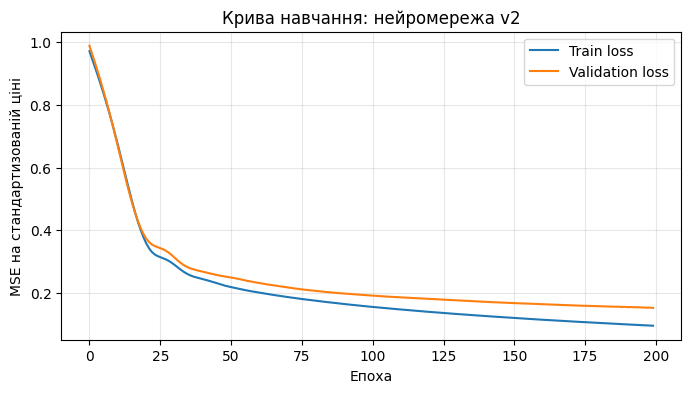

Модель збережено: models/nn_v2.pt


In [ ]:

# Друга архітектура: три приховані шари
housing_nn_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)

print(housing_nn_v2)
print(
    "Кількість параметрів:",
    sum(p.numel() for p in housing_nn_v2.parameters())
)

optimizer_v2 = torch.optim.Adam(
    housing_nn_v2.parameters(),
    lr=0.001
)
loss_fn_v2 = torch.nn.MSELoss()

writer_v2 = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "nn_v2")
)

EPOCHS_V2 = 200
train_losses_v2 = []
val_losses_v2 = []

for epoch in range(EPOCHS_V2):
    housing_nn_v2.train()

    optimizer_v2.zero_grad()
    pred = housing_nn_v2(x_train_t)
    loss = loss_fn_v2(pred, y_train_t)
    loss.backward()
    optimizer_v2.step()

    housing_nn_v2.eval()
    with torch.no_grad():
        val_loss = loss_fn_v2(
            housing_nn_v2(x_val_t), y_val_t
        ).item()

    train_losses_v2.append(loss.item())
    val_losses_v2.append(val_loss)

    writer_v2.add_scalar("Loss/train", loss.item(), epoch)
    writer_v2.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == EPOCHS_V2 - 1:
        print(
            f"Epoch {epoch + 1:3d}/{EPOCHS_V2} | "
            f"train_loss={loss.item():.4f} | "
            f"val_loss={val_loss:.4f}"
        )

writer_v2.close()

# Графік навчання
plt.figure(figsize=(8, 4))
plt.plot(train_losses_v2, label="Train loss")
plt.plot(val_losses_v2, label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("MSE на стандартизованій ціні")
plt.title("Крива навчання: нейромережа v2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Збереження моделі
torch.save(
    housing_nn_v2.cpu().state_dict(),
    "models/nn_v2.pt"
)
housing_nn_v2.to(device)

print("Модель збережено: models/nn_v2.pt")


Друга нейромережа навчається стабільно: train_loss зменшився до 0.0956, а val_loss — до 0.1524. Перевірочна помилка теж продовжує знижуватися наприкінці навчання, тож явних ознак перенавчання за цими значеннями не видно.

In [ ]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import torch

def get_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "MSE": round(mse, 2),
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2),
        "R2": round(r2, 4)
    }

# Перевіряємо першу нейромережу
housing_nn.eval()
with torch.no_grad():
    pred_v1_scaled = housing_nn(x_test_t).cpu().numpy()

pred_v1 = scaler_y.inverse_transform(
    pred_v1_scaled
).ravel()

# Перевіряємо другу нейромережу
housing_nn_v2.eval()
with torch.no_grad():
    pred_v2_scaled = housing_nn_v2(x_test_t).cpu().numpy()

pred_v2 = scaler_y.inverse_transform(
    pred_v2_scaled
).ravel()

# Порівнюємо результати
results_v1 = get_metrics(y_test_true, pred_v1)
results_v2 = get_metrics(y_test_true, pred_v2)

print("Нейромережа v1:", results_v1)
print("Нейромережа v2:", results_v2)


Нейромережа v1: {'MSE': 27318577152.0, 'RMSE': np.float64(165283.32), 'MAE': 94810.47, 'R2': 0.8374}
Нейромережа v2: {'MSE': 20532078592.0, 'RMSE': np.float64(143290.19), 'MAE': 81000.54, 'R2': 0.8778}


Зважаючи на результати, nn_v2 поки що найкраща модель: вона показала кращі результати за всіма чотирма метриками.MAE другої мережі приблизно на 14,6% нижчий, ніж у першої. Це означає, що на цій тестовій вибірці її прогнози в середньому ближчі до фактичних цін.


Навчання nn_exp1, lr=0.0003, шари=[128, 64, 32]
Train loss: 0.1835 | Val loss: 0.2185
Збережено: models/nn_exp1.pt


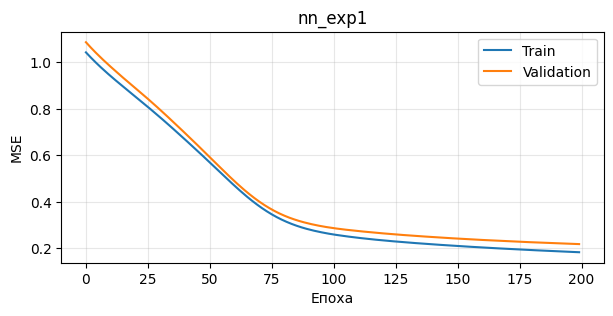


Навчання nn_exp2, lr=0.003, шари=[128, 64, 32]
Train loss: 0.0673 | Val loss: 0.1365
Збережено: models/nn_exp2.pt


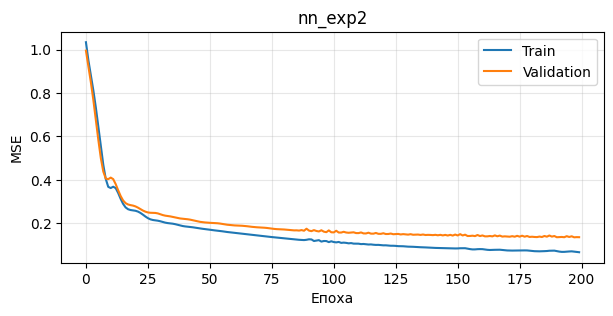


Навчання nn_exp3, lr=0.001, шари=[64, 32]
Train loss: 0.1687 | Val loss: 0.2017
Збережено: models/nn_exp3.pt


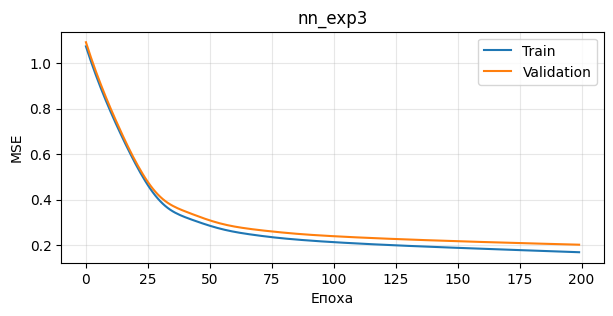


Усі три експерименти завершено.


In [ ]:

import os
import torch
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter

os.makedirs("models", exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

experiments = [
    {
        "name": "nn_exp1",
        "hidden": [128, 64, 32],
        "lr": 0.0003
    },
    {
        "name": "nn_exp2",
        "hidden": [128, 64, 32],
        "lr": 0.003
    },
    {
        "name": "nn_exp3",
        "hidden": [64, 32],
        "lr": 0.001
    }
]

experiment_models = {}

for exp in experiments:
    name = exp["name"]
    hidden = exp["hidden"]
    lr = exp["lr"]

    # Створюємо архітектуру
    layers = []
    in_features = n_features

    for units in hidden:
        layers.append(torch.nn.Linear(in_features, units))
        layers.append(torch.nn.ReLU())
        in_features = units

    layers.append(torch.nn.Linear(in_features, 1))

    model = torch.nn.Sequential(*layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    writer = SummaryWriter(
        log_dir=os.path.join(RUNS_DIR, name)
    )

    train_losses = []
    val_losses = []
    epochs = 200

    print(f"\nНавчання {name}, lr={lr}, шари={hidden}")

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()

        pred = model(x_train_t)
        loss = loss_fn(pred, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(
                model(x_val_t), y_val_t
            ).item()

        train_losses.append(loss.item())
        val_losses.append(val_loss)

        writer.add_scalar("Loss/train", loss.item(), epoch)
        writer.add_scalar("Loss/val", val_loss, epoch)

    writer.close()

    # Зберігаємо модель
    torch.save(
        model.cpu().state_dict(),
        f"models/{name}.pt"
    )
    model.to(device)

    experiment_models[name] = model

    print(
        f"Train loss: {train_losses[-1]:.4f} | "
        f"Val loss: {val_losses[-1]:.4f}"
    )
    print(f"Збережено: models/{name}.pt")

    # Графік конкретного експерименту
    plt.figure(figsize=(7, 3))
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses, label="Validation")
    plt.title(name)
    plt.xlabel("Епоха")
    plt.ylabel("MSE")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

print("\nУсі три експерименти завершено.")


In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Якщо y_test_true ще не створено, беремо фактичні ціни з y_test
y_test_true = y_test.ravel()

def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# Усі моделі, які порівнюємо
models_to_compare = {
    "linear": linear_model,
    "nn_v1": housing_nn,
    "nn_v2": housing_nn_v2,
    **experiment_models
}

results = []

for name, model in models_to_compare.items():
    model.eval()

    with torch.no_grad():
        pred_scaled = model(x_test_t).cpu().numpy()

    # Повертаємо прогнозовані ціни до початкового масштабу
    pred_prices = scaler_y.inverse_transform(pred_scaled).ravel()

    metrics = calculate_metrics(y_test_true, pred_prices)

    results.append({
        "model": name,
        **metrics
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE").reset_index(drop=True)

print("Порівняння моделей на тестовій вибірці:")
display(results_df.round(4))

print("\nНайкраща модель за RMSE:", results_df.iloc[0]["model"])


Порівняння моделей на тестовій вибірці:


,model,MSE,RMSE,MAE,R2
0,nn_exp2,1.809731e+10,134526.2341,74190.0000,0.8923
1,nn_v2,2.053208e+10,143290.1901,81000.5391,0.8778
2,nn_v1,2.731858e+10,165283.3239,94810.4688,0.8374
3,nn_exp3,2.999062e+10,173177.9925,99865.4453,0.8215
4,nn_exp1,3.138790e+10,177166.3000,102842.4297,0.8132
5,linear,5.880695e+10,242501.4388,135229.0156,0.6500



Найкраща модель за RMSE: nn_exp2


In [ ]:

os.makedirs("results", exist_ok=True)

results_df.to_csv(
    "results/results.csv",
    index=False,
    float_format="%.4f"
)

print("Результати збережено у файлі results/results.csv")


Результати збережено у файлі results/results.csv


---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [ ]:
!pip install -q gradio

In [ ]:

import gradio as gr
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Усі навчені моделі
models = {
    "Лінійна регресія": linear_model,
    "Нейромережа v1": housing_nn,
    "Нейромережа v2": housing_nn_v2,
    "Експеримент 1 (lr=0.0003)": experiment_models["nn_exp1"],
    "Експеримент 2 (lr=0.003)": experiment_models["nn_exp2"],
    "Експеримент 3 (менша мережа)": experiment_models["nn_exp3"],
}

# Ознаки, які використовувалися під час навчання
feature_cols = list(X_train_df.columns)

def predict_all(*feature_values):
    # Створюємо таблицю з ознаками в правильному порядку
    input_df = pd.DataFrame(
        [feature_values],
        columns=feature_cols
    )

    # Використовуємо той самий scaler, що й під час навчання
    x_scaled = scaler_X.transform(input_df).astype(np.float32)
    x_tensor = torch.tensor(x_scaled, dtype=torch.float32).to(device)

    predictions = {}

    for name, model in models.items():
        model.eval()
        with torch.no_grad():
            pred_scaled = model(x_tensor).cpu().numpy()

        # Повертаємо прогноз до початкового масштабу цін
        pred_price = scaler_y.inverse_transform(pred_scaled)[0, 0]
        predictions[name] = float(pred_price)

    return predictions


def run_prediction(selected_model, *feature_values):
    predictions = predict_all(*feature_values)

    selected_prediction = predictions[selected_model]

    fig, ax = plt.subplots(figsize=(10, 5))
    names = list(predictions.keys())
    values = list(predictions.values())

    bars = ax.bar(names, values)

    ax.set_ylabel("Прогнозована ціна, дол. США")
    ax.set_title("Порівняння прогнозів моделей")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"${value:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

    plt.tight_layout()

    return round(selected_prediction, 2), fig


with gr.Blocks(title="Прогноз вартості будинків") as demo:
    gr.Markdown(
        "# Прогноз вартості будинку\n"
        "Введіть характеристики будинку, щоб порівняти прогнози "
        "лінійної регресії та п'яти нейромереж."
    )

    with gr.Row():
        with gr.Column():
            sliders = []

            for col in feature_cols:
                sliders.append(
                    gr.Slider(
                        minimum=float(X_train_df[col].min()),
                        maximum=float(X_train_df[col].max()),
                        value=float(X_train_df[col].median()),
                        label=col,
                        step=1 if X_train_df[col].nunique() < 20 else 0.1
                    )
                )

            model_choice = gr.Dropdown(
                choices=list(models.keys()),
                value="Експеримент 2 (lr=0.003)",
                label="Модель для відображення прогнозу"
            )

            submit_btn = gr.Button(
                "Розрахувати прогноз",
                variant="primary"
            )

        with gr.Column():
            prediction_output = gr.Number(
                label="Прогноз обраної моделі (дол. США)"
            )
            comparison_plot = gr.Plot(
                label="Порівняння всіх моделей"
            )

    submit_btn.click(
        fn=run_prediction,
        inputs=[model_choice] + sliders,
        outputs=[prediction_output, comparison_plot]
    )

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://fb4b6bd3ff55bc2a74.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://fb4b6bd3ff55bc2a74.gradio.live


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
```